# Phase 4: Distribution Shift Experiments

## Goals
- Evaluate calibration degradation under temporal shift (sliding windows)
- Test robustness under synthetic shifts (covariate, new fraud modes, label noise)
- Compare which calibration methods are most robust to shift
- Design and test recalibration strategies with limited labels

In [3]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils.helpers import load_config, set_seed
from src.data.loader import load_creditcard, preprocess_creditcard
from src.data.splits import temporal_split_creditcard, sliding_window_splits
from src.models.baselines import get_model
from src.calibration.post_hoc import get_calibrator, CALIBRATORS
from src.evaluation.calibration_metrics import compute_all_calibration_metrics
from src.evaluation.visualization import plot_calibration_over_time
from src.shifts.shift_generator import create_shift_scenarios

config = load_config('../configs/config.yaml')
set_seed(config['experiment']['seed'])
print('Setup complete.')

Setup complete.


In [4]:
# Load data
# Split FIRST, then preprocess with train-only statistics (leakage-free)
df_raw = load_creditcard(f"../{config['data']['creditcard_path']}")
splits = temporal_split_creditcard(df_raw)
X, y = preprocess_creditcard(df_raw, train_idx=splits['train'])
X_train, y_train = X.iloc[splits['train']].values, y[splits['train']]
X_cal, y_cal = X.iloc[splits['calibration']].values, y[splits['calibration']]

model = get_model('xgboost', config['models']['xgboost'])
model.fit(X_train, y_train)
print('Model trained.')

[0]	validation_0-aucpr:0.67333


c:\Users\debas\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:17:56] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[100]	validation_0-aucpr:0.98297
[200]	validation_0-aucpr:1.00000
[300]	validation_0-aucpr:1.00000
[400]	validation_0-aucpr:1.00000
[499]	validation_0-aucpr:1.00000
Model trained.


## Experiment 1: Temporal Calibration Degradation

In [5]:
# Sliding window evaluation
windows = sliding_window_splits(
    df_raw['Time'].values,
    n_windows=config['shifts']['temporal']['n_windows'],
    train_window_frac=0.5,
    cal_frac=0.1,
)

# For each window: get raw predictions, calibrate, measure ECE
window_metrics = []

# Fit calibrators on calibration set
raw_cal_probs = model.predict_proba(X_cal)
calibrators = {}
for cal_name in CALIBRATORS.keys():
    calibrators[cal_name] = get_calibrator(cal_name)
    calibrators[cal_name].fit(raw_cal_probs, y_cal)

for w in windows:
    X_w = X.iloc[w['test']].values
    y_w = y[w['test']]
    raw_probs = model.predict_proba(X_w)
    
    metrics = {'Uncalibrated': compute_all_calibration_metrics(raw_probs, y_w)['ece']}
    for cal_name, calibrator in calibrators.items():
        cal_probs = calibrator.calibrate(raw_probs)
        metrics[cal_name] = compute_all_calibration_metrics(cal_probs, y_w)['ece']
    
    window_metrics.append(metrics)
    print(f"Window {w['window_id']}: {metrics}")

print('\nTemporal evaluation complete.')

c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide

Window 0: {'Uncalibrated': np.float64(0.0003774554836112519), 'temperature_scaling': np.float64(0.00023521764150745381), 'platt_scaling': np.float64(0.00018412594044754004), 'isotonic_regression': np.float64(3.290176257476643e-05), 'beta_calibration': np.float64(0.00027261293146036493), 'histogram_binning': np.float64(2.739461202634303e-05)}
Window 1: {'Uncalibrated': np.float64(0.0002647145084711028), 'temperature_scaling': np.float64(0.0001011639889667984), 'platt_scaling': np.float64(0.00013793114834007134), 'isotonic_regression': np.float64(8.635735755458961e-05), 'beta_calibration': np.float64(0.00015879547973062045), 'histogram_binning': np.float64(7.62660735407929e-05)}
Window 2: {'Uncalibrated': np.float64(0.00039822594033435275), 'temperature_scaling': np.float64(0.0002425628205138932), 'platt_scaling': np.float64(0.00014401186785175692), 'isotonic_regression': np.float64(0.00014939623662257875), 'beta_calibration': np.float64(0.0002907514621746113), 'histogram_binning': np.fl

c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)


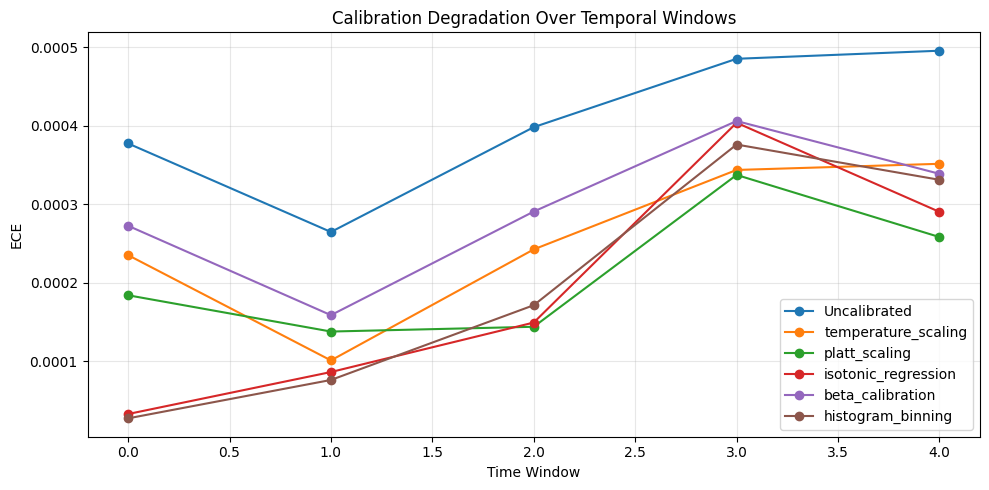

In [6]:
# Plot calibration degradation over time
fig = plot_calibration_over_time(
    window_metrics,
    metric_name='ECE',
    title='Calibration Degradation Over Temporal Windows'
)
plt.savefig('../results/figures/calibration_degradation.png', dpi=150, bbox_inches='tight')
plt.show()

## Experiment 2: Synthetic Shift Robustness

In [7]:
# Generate shift scenarios
X_test_df = X.iloc[splits['test']]
y_test = y[splits['test']]

scenarios = create_shift_scenarios(X_test_df, y_test, config['shifts']['synthetic'])

shift_results = {}
for scenario_name, (X_s, y_s) in scenarios.items():
    print(f'\nScenario: {scenario_name}')
    X_s_vals = X_s.values if hasattr(X_s, 'values') else X_s
    raw_probs = model.predict_proba(X_s_vals)
    
    scenario_metrics = {
        'Uncalibrated': compute_all_calibration_metrics(raw_probs, y_s)
    }
    
    for cal_name, calibrator in calibrators.items():
        cal_probs = calibrator.calibrate(raw_probs)
        scenario_metrics[cal_name] = compute_all_calibration_metrics(cal_probs, y_s)
    
    shift_results[scenario_name] = scenario_metrics
    
    # Print ECE for each method
    ece_summary = {k: v['ece'] for k, v in scenario_metrics.items()}
    print(f'  ECE: {ece_summary}')


Scenario: no_shift
  ECE: {'Uncalibrated': np.float64(0.00046954826014534447), 'temperature_scaling': np.float64(0.00032786885110060475), 'platt_scaling': np.float64(0.00012588294190859142), 'isotonic_regression': np.float64(0.0003001656330516863), 'beta_calibration': np.float64(0.0003366131187078629), 'histogram_binning': np.float64(0.0002759740718769528)}

Scenario: mild_covariate_shift


c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide

  ECE: {'Uncalibrated': np.float64(0.0004368195018265296), 'temperature_scaling': np.float64(0.000289138255830401), 'platt_scaling': np.float64(7.69024871090651e-05), 'isotonic_regression': np.float64(0.00022860993752294513), 'beta_calibration': np.float64(0.0003044651589543201), 'histogram_binning': np.float64(0.0001980802465655313)}

Scenario: strong_covariate_shift
  ECE: {'Uncalibrated': np.float64(0.0004402545930345732), 'temperature_scaling': np.float64(0.00022761727801787557), 'platt_scaling': np.float64(9.745777255533608e-05), 'isotonic_regression': np.float64(0.0001662949899887837), 'beta_calibration': np.float64(0.00023196294966587383), 'histogram_binning': np.float64(0.00017949428021742442)}

Scenario: new_fraud_mode


c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide

  ECE: {'Uncalibrated': np.float64(0.01633607356399561), 'temperature_scaling': np.float64(0.01645971507171528), 'platt_scaling': np.float64(0.01915336996261314), 'isotonic_regression': np.float64(0.01838611467592507), 'beta_calibration': np.float64(0.018470908413206914), 'histogram_binning': np.float64(0.01888628578706731)}

Scenario: label_noise
  ECE: {'Uncalibrated': np.float64(0.02045924911684681), 'temperature_scaling': np.float64(0.02031756970780207), 'platt_scaling': np.float64(0.020115583798610056), 'isotonic_regression': np.float64(0.02028986648975315), 'beta_calibration': np.float64(0.020285087624077186), 'histogram_binning': np.float64(0.020265674928578416)}

Scenario: combined_shift
  ECE: {'Uncalibrated': np.float64(0.009448560132551591), 'temperature_scaling': np.float64(0.0093237202823751), 'platt_scaling': np.float64(0.01162233681476895), 'isotonic_regression': np.float64(0.01108678246956036), 'beta_calibration': np.float64(0.010820168062945815), 'histogram_binning': n

c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)


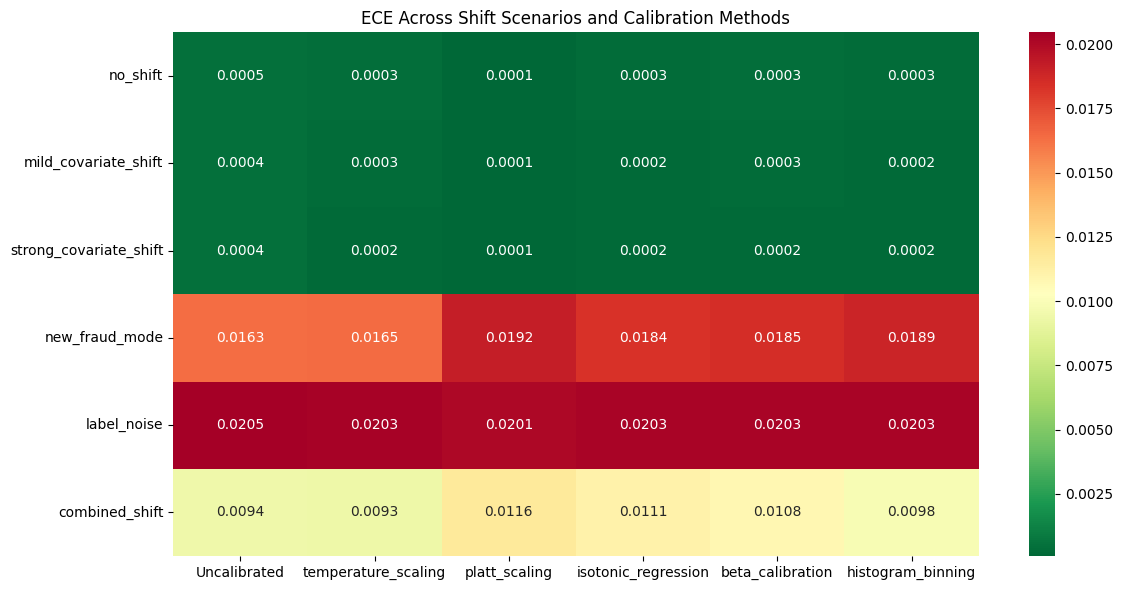

In [8]:
# Heatmap of ECE across scenarios and methods
ece_matrix = pd.DataFrame({
    scenario: {method: metrics['ece'] for method, metrics in methods.items()}
    for scenario, methods in shift_results.items()
}).T

fig, ax = plt.subplots(figsize=(12, 6))
import seaborn as sns
sns.heatmap(ece_matrix, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=ax)
ax.set_title('ECE Across Shift Scenarios and Calibration Methods')
plt.tight_layout()
plt.savefig('../results/figures/shift_ece_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

ece_matrix.to_csv('../results/tables/shift_ece_comparison.csv')

## Experiment 3: Recalibration with Limited Labels

Simulate a scenario where we get a small batch of new labeled data
from the shifted distribution and recalibrate.

In [9]:
# Take the 'strong_covariate_shift' scenario
X_shifted, y_shifted = scenarios['strong_covariate_shift']
X_shifted_vals = X_shifted.values if hasattr(X_shifted, 'values') else X_shifted

# Simulate getting limited labels from shifted distribution
recal_sizes = [50, 100, 200, 500, 1000]
recal_results = {size: {} for size in recal_sizes}

raw_probs_shifted = model.predict_proba(X_shifted_vals)

for n_recal in recal_sizes:
    # Sample n_recal points for recalibration
    idx = np.random.choice(len(y_shifted), size=min(n_recal, len(y_shifted)), replace=False)
    remaining = np.setdiff1d(np.arange(len(y_shifted)), idx)
    
    for cal_name in ['temperature_scaling', 'isotonic_regression', 'platt_scaling']:
        calibrator = get_calibrator(cal_name)
        calibrator.fit(raw_probs_shifted[idx], y_shifted[idx])
        recal_probs = calibrator.calibrate(raw_probs_shifted[remaining])
        metrics = compute_all_calibration_metrics(recal_probs, y_shifted[remaining])
        recal_results[n_recal][cal_name] = metrics['ece']

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
for cal_name in ['temperature_scaling', 'isotonic_regression', 'platt_scaling']:
    values = [recal_results[s][cal_name] for s in recal_sizes]
    ax.plot(recal_sizes, values, marker='o', label=cal_name)

ax.axhline(y=compute_all_calibration_metrics(raw_probs_shifted, y_shifted)['ece'],
           color='red', linestyle='--', label='Uncalibrated')
ax.set_xlabel('Recalibration Set Size')
ax.set_ylabel('ECE')
ax.set_title('Recalibration Effectiveness with Limited Shifted Labels')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/recalibration_effectiveness.png', dpi=150, bbox_inches='tight')
plt.show()

ValueError: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(0)

## Key Findings

1. How much does calibration degrade over temporal windows?
2. Which shifts cause the most calibration damage?
3. Which calibration methods are most robust to shift?
4. How many recalibration samples are needed to restore calibration?
5. Are parametric or non-parametric calibrators more robust?